
**IND320 – Project Work, Part 3: Data Quality**


This project investigates weather data and reservoir filling data in Norway. Geographical data from NVE are used to identify precipitation regions and electricity areas. Hourly historical weather data for 2024 are retrieved from the Open-Meteo Historical Weather API using the ERA5 reanalysis model. Precipitation observations are examined using Discrete Cosine Transform (DCT) filtering and robust Statistical Process Control (SPC), while temperature anomalies are identified using Local Outlier Factor (LOF). Weekly reservoir filling data are analysed using Seasonal-Trend decomposition using LOESS (STL) and spectrogram analysis.


The objectives of this project are:

1. Retrieve hourly ERA5 temperature and precipitation data for the NO3 electricity area for 2024.
2. Use DCT filtering and robust SPC limits to identify unusual precipitation observations.
3. Use LOF to identify unusual temperature observations.
4. Apply STL decomposition to weekly reservoir filling data.
5. Use spectrogram analysis to investigate how the frequency content of reservoir filling changes over time.
6. Discuss the results, assumptions and limitations of the methods.

#####  Libraries and project setup

The notebook uses GeoPandas for geographical data, Requests for API access, Pandas and NumPy for data processing, SciPy for signal processing, scikit-learn for LOF, and Statsmodels for STL.

#### Import Libraries and Define Project Paths

In [22]:
from pathlib import Path
import os
import requests
import time

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from scipy.fft import dct, idct
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL

# Find the Part3 folder
current = Path.cwd()

PROJECT_DIR = None

for folder in [current, *current.parents]:
    if folder.name.lower() == "part3":
        PROJECT_DIR = folder
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find the Part3 project folder."
    )

# Define project paths
DATA_DIR = PROJECT_DIR / "data"
WEATHER_DIR = DATA_DIR / "weather"
SHAPEFILE_DIR = WEATHER_DIR / "shapefiles"

PRECIPITATION_DIR = SHAPEFILE_DIR / "precipitation_areas"
ELECTRICITY_DIR = SHAPEFILE_DIR / "electricity_areas"
NO3_DIR = WEATHER_DIR / "NO3"

NO3_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Precipitation shapefile:",
      PRECIPITATION_DIR / "NVE_Region.shp")
print("Electricity GeoJSON:",
      ELECTRICITY_DIR / "electricity_areas.geojson")

Project directory: c:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part3
Precipitation shapefile: c:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part3\data\weather\shapefiles\precipitation_areas\NVE_Region.shp
Electricity GeoJSON: c:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part3\data\weather\shapefiles\electricity_areas\electricity_areas.geojson


This section imports the Python libraries required for the project and defines the paths to the input data and output folders. The libraries support data processing, geographical analysis, statistical analysis, visualization, and time series analysis. Defining project paths in one place makes the notebook easier to organize and maintain.

##### Geographical data

The project uses two geographical datasets: NVE precipitation regions and electricity price areas. The precipitation dataset contains the region identifiers RV, RM, RN, RØ and RS. The electricity dataset contains NO1, NO2, NO3, NO4 and NO5.

Both datasets are transformed to the same coordinate reference system before spatial operations. The data shown in the notebook use EPSG:25833.

In [4]:
# Define file paths
shapefile_path = PRECIPITATION_DIR / "NVE_Region.shp"
electricity_path = ELECTRICITY_DIR / "electricity_areas.geojson"

# Read geographical data
precipitation = gpd.read_file(shapefile_path)
electricity = gpd.read_file(electricity_path)

# Match coordinate reference systems
electricity = electricity.to_crs(precipitation.crs)

print("Precipitation regions:")
display(precipitation[["REGION", "REGIONNAVN"]])

print("\nElectricity regions:")
display(electricity[["ElSpotOmr"]])

print("\nPrecipitation CRS:", precipitation.crs)
print("Electricity CRS:", electricity.crs)

Precipitation regions:


,REGION,REGIONNAVN
0,RV,Region Vest
1,RM,Region Midt-Norge
2,RN,Region Nord
3,RÃ,Region Ãst
4,RS,Region SÃ¸r



Electricity regions:


,ElSpotOmr
0,NO2
1,NO5
2,NO1
3,NO3
4,NO4



Precipitation CRS: EPSG:25833
Electricity CRS: EPSG:25833


####  Visualize Precipitation and Electricity Areas

c:\Users\Khali\anaconda3\Lib\site-packages\geopandas\plotting.py:1339: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\Users\Khali\anaconda3\Lib\site-packages\geopandas\plotting.py:702: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\Users\Khali\anaconda3\Lib\site-packages\geopandas\plotting.py:702: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\Users\Khali\anaconda3\Lib\site-packages\geopandas\plotting.py:702: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\Users\Khali\anaconda3\Lib\site-packages\geopandas\plotting.py:702: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\Users\Khali\anaconda3\Lib\site-packages\geopandas\plotting.py:702: UserWarning: Glyph 152 (\x98) missing from font(s) DejaVu Sans.
  ax.figure.canvas.draw_idle()
c:\Users\

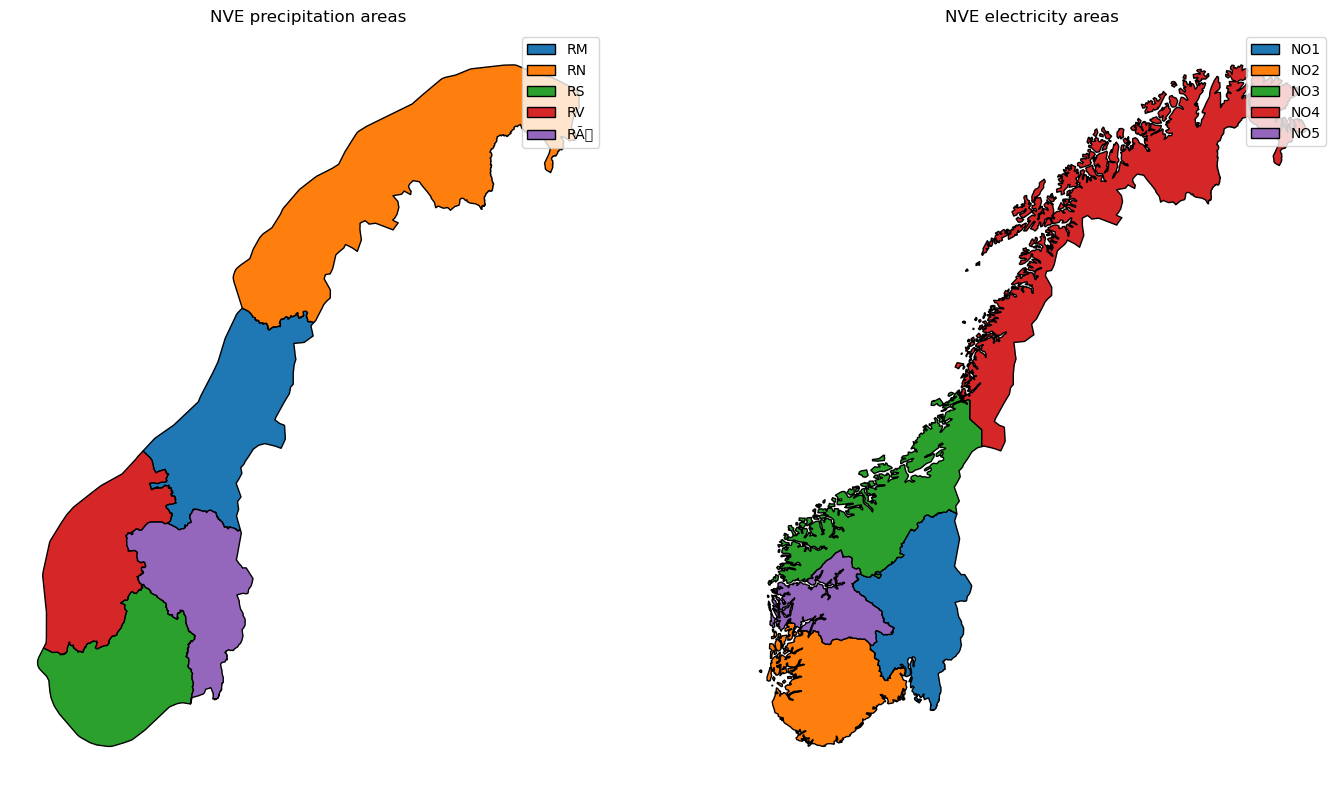

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8))

precipitation.plot(
    ax=axes[0],
    column="REGION",
    categorical=True,
    legend=True,
    edgecolor="black"
)
axes[0].set_title("NVE precipitation areas")

electricity.plot(
    ax=axes[1],
    column="ElSpotOmr",
    categorical=True,
    legend=True,
    edgecolor="black"
)
axes[1].set_title("NVE electricity areas")

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

#### Generate Random Geographical Points

In [24]:
random_points_file = WEATHER_DIR / "random_points_2024.csv"

if random_points_file.exists():
    random_points = pd.read_csv(random_points_file)

else:
    precipitation_projected = precipitation.to_crs(epsg=3035)

    sampled_geometry = precipitation_projected.geometry.sample_points(
        size=1000,
        random_state=42
    )

    sampled = gpd.GeoDataFrame(
        {
            "REGION": precipitation_projected["REGION"].values,
            "REGIONNAVN": precipitation_projected["REGIONNAVN"].values
        },
        geometry=sampled_geometry,
        crs=precipitation_projected.crs
    )

    sampled = sampled.explode(
        index_parts=False
    ).reset_index(drop=True)

    sampled = sampled.to_crs(epsg=4326)

    sampled["longitude"] = sampled.geometry.x
    sampled["latitude"] = sampled.geometry.y
    sampled["point_id"] = range(1, len(sampled) + 1)

    random_points = sampled[
        [
            "point_id",
            "REGION",
            "REGIONNAVN",
            "latitude",
            "longitude"
        ]
    ].copy()

    random_points.to_csv(random_points_file, index=False)

display(random_points.head())

,point_id,REGION,REGIONNAVN,latitude,longitude
0,1,RV,Region Vest,60.039234,6.721828
1,2,RV,Region Vest,60.668783,7.090920
2,3,RV,Region Vest,62.608753,5.845186
3,4,RV,Region Vest,61.319713,4.347294
4,5,RV,Region Vest,62.585006,8.230929


The table shows five sample points from Region Vest (RV). Each point has a unique ID and its own latitude and longitude. The points are located in different parts of the region. These coordinates will be used to collect weather data from the Open-Meteo API.

#### Spatial Join: Assign Electricity Areas to Points

In [26]:
# Convert sampled coordinates to GeoDataFrame
points_gdf = gpd.GeoDataFrame(
    random_points.copy(),
    geometry=gpd.points_from_xy(
        random_points["longitude"],
        random_points["latitude"]
    ),
    crs="EPSG:4326"
)

# Match CRS with electricity polygons
points_gdf = points_gdf.to_crs(electricity.crs)

# Spatially assign electricity area to each point
points_with_electricity = gpd.sjoin(
    points_gdf,
    electricity[["ElSpotOmr", "geometry"]],
    how="left",
    predicate="within"
)

# Keep the point information and assigned electricity area
points_with_electricity = points_with_electricity.drop(
    columns=["index_right"],
    errors="ignore"
)

display(
    points_with_electricity[
        ["point_id", "REGION", "ElSpotOmr"]
    ].head()
)

,point_id,REGION,ElSpotOmr
0,1,RV,NO2
1,2,RV,NO5
2,3,RV,NaN
3,4,RV,NaN
4,5,RV,NO3


There are from Region Vest (RV) are linked to electricity price areas (ElSpotOmr). Three points are matched to NO2, NO5, and NO3, while two points have missing values (NaN). This means that not all sampled points could be linked to an electricity price area. These missing values should be considered in the next steps of the analysis.

#### Download Historical Weather Data from Open-Meteo



In [27]:
BASE_URL = "https://archive-api.open-meteo.com/v1/archive"


def download_weather_data(
    region_id,
    start_date,
    end_date,
    points_df,
    batch_size=10,
    output_file=None
):
    """
    Download hourly ERA5 weather data for an electricity region.

    Parameters
    ----------
    region_id : str
        Electricity region, e.g. NO3.
    start_date : str
        Start date in YYYY-MM-DD format.
    end_date : str
        End date in YYYY-MM-DD format.
    points_df : DataFrame
        Must contain ElSpotOmr, point_id, latitude and longitude.
    batch_size : int
        Number of locations per API request.
    output_file : Path or None
        Optional CSV output file.

    Returns
    -------
    DataFrame
        Hourly temperature and precipitation observations.
    """

    locations = points_df[
        points_df["ElSpotOmr"].astype(str).str.upper()
        == region_id.upper()
    ].copy()

    locations = locations.dropna(
        subset=["latitude", "longitude"]
    )

    if locations.empty:
        raise ValueError(
            f"No sampled locations found for {region_id}."
        )

    session = requests.Session()
    all_batches = []

    total_batches = (
        len(locations) + batch_size - 1
    ) // batch_size

    for batch_number, start in enumerate(
        range(0, len(locations), batch_size),
        start=1
    ):

        batch = locations.iloc[start:start + batch_size]

        params = {
            "latitude": ",".join(
                batch["latitude"].astype(str)
            ),
            "longitude": ",".join(
                batch["longitude"].astype(str)
            ),
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,precipitation",
            "models": "era5",
            "timezone": "UTC"
        }

        for attempt in range(8):
            response = session.get(
                BASE_URL,
                params=params,
                timeout=180
            )

            if response.status_code == 429:
                wait_time = min(60 * (attempt + 1), 600)
                print(
                    f"Rate limit. Waiting {wait_time} seconds."
                )
                time.sleep(wait_time)
                continue

            response.raise_for_status()
            break

        else:
            raise RuntimeError(
                f"Batch {batch_number} failed after retries."
            )

        results = response.json()

        if isinstance(results, dict):
            results = [results]

        if len(results) != len(batch):
            raise ValueError(
                "API response count does not match batch size."
            )

        batch_data = []

        for point, result in zip(
            batch.itertuples(index=False),
            results
        ):

            hourly = result["hourly"]

            weather = pd.DataFrame({
                "time": hourly["time"],
                "temperature_2m": hourly["temperature_2m"],
                "precipitation": hourly["precipitation"]
            })

            weather["point_id"] = point.point_id
            weather["latitude"] = point.latitude
            weather["longitude"] = point.longitude
            weather["region"] = region_id

            batch_data.append(weather)

        batch_df = pd.concat(
            batch_data,
            ignore_index=True
        )

        all_batches.append(batch_df)

        # Save completed batch
        if output_file is not None:
            batch_df.to_csv(
                output_file,
                mode="a" if Path(output_file).exists() else "w",
                header=not Path(output_file).exists(),
                index=False
            )

        print(
            f"Batch {batch_number}/{total_batches} completed."
        )

        if batch_number < total_batches:
            time.sleep(10)

    return pd.concat(all_batches, ignore_index=True)

In [29]:
NO3_points = points_with_electricity[
    points_with_electricity["ElSpotOmr"] == "NO3"
].copy()

NO3_points = NO3_points[
    [
        "point_id",
        "latitude",
        "longitude",
        "ElSpotOmr"
    ]
].copy()

print("NO3 locations:", len(NO3_points))

NO3 locations: 817


#### Select NO3 Electricity Area Locations

In [30]:
NO3_weather_file = WEATHER_DIR / "NO3_weather_2024.csv"
NO3_average_file = NO3_DIR / "NO3_weather_average_2024.csv"

if NO3_average_file.exists():
    NO3_weather_average = pd.read_csv(NO3_average_file)
    print("Using existing average weather data.")

elif NO3_weather_file.exists():
    NO3_weather = pd.read_csv(NO3_weather_file)

    NO3_weather["time"] = pd.to_datetime(
        NO3_weather["time"]
    )

    NO3_weather_average = (
        NO3_weather.groupby("time", as_index=False)
        .agg({
            "temperature_2m": "mean",
            "precipitation": "mean"
        })
    )

    NO3_weather_average.to_csv(
        NO3_average_file,
        index=False
    )

    print("Average weather data created from existing raw data.")

else:
    NO3_weather = download_weather_data(
        region_id="NO3",
        start_date="2024-01-01",
        end_date="2024-12-31",
        points_df=points_with_electricity,
        batch_size=10,
        output_file=NO3_weather_file
    )

    NO3_weather_average = (
        NO3_weather.groupby("time", as_index=False)
        .agg({
            "temperature_2m": "mean",
            "precipitation": "mean"
        })
    )

    NO3_weather_average.to_csv(
        NO3_average_file,
        index=False
    )

NO3_weather_average["time"] = pd.to_datetime(
    NO3_weather_average["time"]
)

NO3_weather_average = NO3_weather_average.sort_values(
    "time"
).reset_index(drop=True)

display(NO3_weather_average.head())

Using existing average weather data.


,time,temperature_2m,precipitation
0,2024-01-01 00:00:00,-6.105858,0.005160
1,2024-01-01 01:00:00,-6.180195,0.005160
2,2024-01-01 02:00:00,-6.334589,0.004742
3,2024-01-01 03:00:00,-6.293724,0.004742
4,2024-01-01 04:00:00,-6.316318,0.004742


The generated geographical points are filtered to select locations assigned to the NO3 electricity area. According to the results, 817 locations belong to NO3. This selection allows the subsequent weather analysis to focus on one electricity area rather than combining observations from different regions.

#### Precipitation Outlier Detection Using DCT and SPC

In [31]:
def analyze_precipitation_spc(
    df,
    cutoff=168,
    n_std=3
):
    """
    Detect precipitation outliers using DCT high-pass filtering
    and robust SPC limits.

    Returns
    -------
    fig : matplotlib Figure
    summary : dict
    """

    data = df.copy()
    data["time"] = pd.to_datetime(data["time"])

    # Average precipitation over time
    avg_precip = (
        data.groupby("time")["precipitation"]
        .mean()
        .sort_index()
    )

    values = avg_precip.to_numpy()

    if len(values) == 0:
        raise ValueError("No precipitation observations found.")

    if not 0 <= cutoff < len(values):
        raise ValueError("cutoff must be between 0 and number of observations.")

    # DCT
    coefficients = dct(
        values,
        type=2,
        norm="ortho"
    )

    # Remove low-frequency coefficients
    filtered_coefficients = coefficients.copy()
    filtered_coefficients[:cutoff] = 0

    # Reconstruct high-pass filtered signal (SATV)
    satv = idct(
        filtered_coefficients,
        type=2,
        norm="ortho"
    )

    # Robust statistics
    median = np.median(satv)
    mad = np.median(np.abs(satv - median))
    robust_sigma = 1.4826 * mad

    # SPC limits on the SATV scale
    upper_limit = median + n_std * robust_sigma
    lower_limit = median - n_std * robust_sigma

    # Identify outliers
    outlier_mask = (
        (satv > upper_limit) |
        (satv < lower_limit)
    )

    # Reconstruct low-frequency baseline
    low_frequency = values - satv

    # Translate SPC limits back to original precipitation scale
    upper_curve = low_frequency + upper_limit
    lower_curve = low_frequency + lower_limit

    outlier_times = avg_precip.index[outlier_mask]

    # Plot original precipitation only
    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        avg_precip.index,
        values,
        label="Average precipitation",
        linewidth=0.8
    )

    ax.plot(
        avg_precip.index,
        upper_curve,
        linestyle="--",
        label="Upper SPC boundary"
    )

    ax.plot(
        avg_precip.index,
        lower_curve,
        linestyle="--",
        label="Lower SPC boundary"
    )

    ax.scatter(
        outlier_times,
        values[outlier_mask],
        color="red",
        label="Outliers",
        s=15,
        zorder=3
    )

    ax.set_title("Average Precipitation with DCT/SPC Outliers")
    ax.set_xlabel("Time")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    summary = {
        "cutoff": cutoff,
        "n_std": n_std,
        "median_SATV": float(median),
        "MAD": float(mad),
        "robust_sigma": float(robust_sigma),
        "upper_SPC_SATV": float(upper_limit),
        "lower_SPC_SATV": float(lower_limit),
        "number_of_outliers": int(outlier_mask.sum()),
        "percentage_outliers": float(outlier_mask.mean() * 100),
        "outlier_times": outlier_times
    }

    return fig, summary

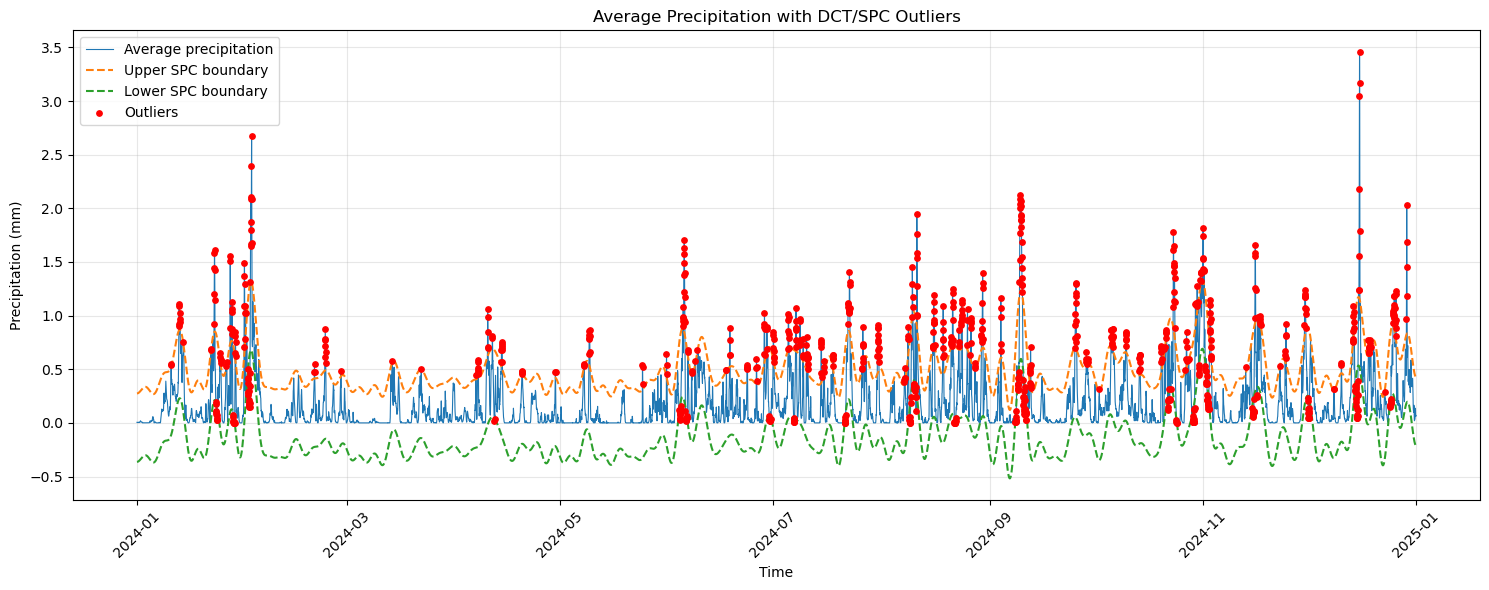

Precipitation outlier summary:
cutoff: 168
n_std: 3
median_SATV: -0.019639485709948598
MAD: 0.0716943268776666
robust_sigma: 0.10629400902882849
upper_SPC_SATV: 0.2992425413765369
lower_SPC_SATV: -0.3385215127964341
number_of_outliers: 822
percentage_outliers: 9.35792349726776

First detected outlier times:
DatetimeIndex(['2024-01-10 18:00:00', '2024-01-10 19:00:00',
               '2024-01-13 00:00:00', '2024-01-13 01:00:00',
               '2024-01-13 02:00:00', '2024-01-13 03:00:00',
               '2024-01-13 05:00:00', '2024-01-13 06:00:00',
               '2024-01-13 07:00:00', '2024-01-14 05:00:00'],
              dtype='datetime64[ns]', name='time', freq=None)


In [32]:
precipitation_fig, precipitation_summary = analyze_precipitation_spc(
    NO3_weather_average,
    cutoff=168,
    n_std=3
)

plt.show()

print("Precipitation outlier summary:")
for key, value in precipitation_summary.items():
    if key != "outlier_times":
        print(f"{key}: {value}")

print("\nFirst detected outlier times:")
print(precipitation_summary["outlier_times"][:10])


The DCT and SPC methods are used to detect unusual changes in precipitation. The DCT removes the low-frequency components and helps identify short-term variations. The analysis then uses the median and MAD to calculate robust control limits. Observations outside these limits are marked as potential outliers. This method is useful because it is less affected by extreme values than standard statistical measures.
The precipitation analysis identifies 822 potential outliers among 8,784 hourly observations, corresponding to approximately 9.36% of the dataset.

These observations differ significantly from the typical values identified by the robust statistical limits. However, an outlier is not necessarily an incorrect measurement. Unusual precipitation values may represent genuine weather events, such as periods of heavy rainfall.


#### Temperature Anomaly Detection Using LOF

In [33]:
def analyze_temperature_lof(
    df,
    contamination=0.01,
    n_neighbors=20
):
    """
    Detect temperature anomalies using Local Outlier Factor.

    Parameters
    ----------
    df : DataFrame
        Must contain time and temperature_2m.
    contamination : float
        Expected proportion of anomalies. Default is 1%.
    n_neighbors : int
        Number of neighbours used by LOF.

    Returns
    -------
    fig : matplotlib Figure
    summary : dict
    """

    data = df.copy()
    data["time"] = pd.to_datetime(data["time"])

    avg_temp = (
        data.groupby("time")["temperature_2m"]
        .mean()
        .sort_index()
    )

    if len(avg_temp) <= n_neighbors:
        raise ValueError(
            "Number of observations must be greater than n_neighbors."
        )

    X = avg_temp.to_numpy().reshape(-1, 1)

    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )

    predictions = lof.fit_predict(X)

    # -1 = anomaly, 1 = normal observation
    anomaly_mask = predictions == -1
    anomaly_times = avg_temp.index[anomaly_mask]

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        avg_temp.index,
        avg_temp.values,
        label="Average temperature",
        linewidth=0.8
    )

    ax.scatter(
        anomaly_times,
        avg_temp.values[anomaly_mask],
        color="red",
        label="Temperature anomalies",
        s=15,
        zorder=3
    )

    ax.set_title("Temperature Anomaly Detection – LOF")
    ax.set_xlabel("Time")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.xticks(rotation=45)
    plt.tight_layout()

    summary = {
        "contamination": contamination,
        "n_neighbors": n_neighbors,
        "total_observations": len(avg_temp),
        "number_of_anomalies": int(anomaly_mask.sum()),
        "percentage_anomalies": float(
            anomaly_mask.mean() * 100
        ),
        "mean_temperature": float(avg_temp.mean()),
        "anomaly_times": anomaly_times
    }

    return fig, summary

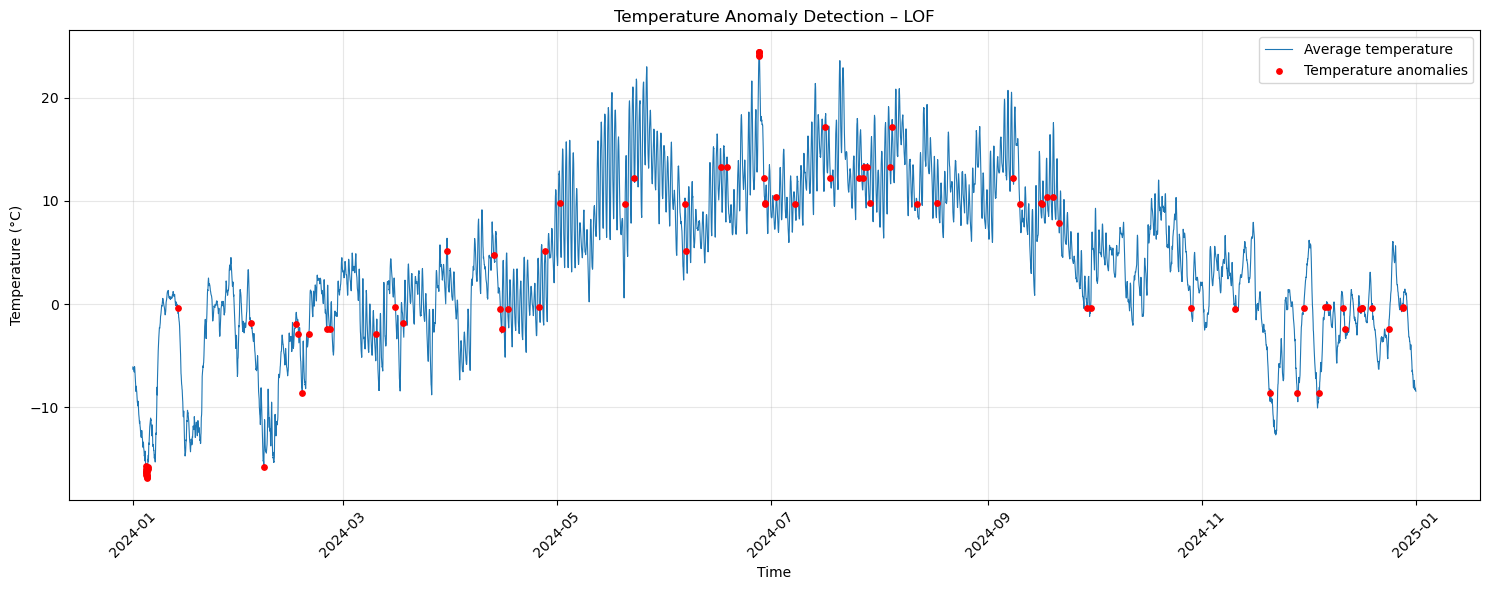

Temperature anomaly summary:
contamination: 0.01
n_neighbors: 20
total_observations: 8784
number_of_anomalies: 88
percentage_anomalies: 1.0018214936247722
mean_temperature: 4.244196291342443

First detected anomaly times:
DatetimeIndex(['2024-01-04 16:00:00', '2024-01-04 17:00:00',
               '2024-01-04 18:00:00', '2024-01-04 19:00:00',
               '2024-01-04 20:00:00', '2024-01-04 21:00:00',
               '2024-01-04 22:00:00', '2024-01-04 23:00:00',
               '2024-01-05 00:00:00', '2024-01-05 01:00:00'],
              dtype='datetime64[ns]', name='time', freq=None)


In [34]:
temperature_fig, temperature_summary = analyze_temperature_lof(
    NO3_weather_average,
    contamination=0.01,
    n_neighbors=20
)

plt.show()

print("Temperature anomaly summary:")

for key, value in temperature_summary.items():
    if key != "anomaly_times":
        print(f"{key}: {value}")

print("\nFirst detected anomaly times:")
print(temperature_summary["anomaly_times"][:10])

Local Outlier Factor (LOF) is used to identify unusual temperature observations. LOF is a density-based anomaly detection method that compares the local density around each observation with the density around its neighbours.

The analysis uses 20 neighbours and a contamination parameter of 0.01. This means that approximately 1% of the observations are expected to be classified as anomalies.


#### Load and Prepare Reservoir Filling Data

In [36]:
reservoir_file = DATA_DIR / "reservoirs.csv"

if not reservoir_file.exists():
    raise FileNotFoundError(reservoir_file)

reservoirs = pd.read_csv(reservoir_file)

reservoirs["dato_Id"] = pd.to_datetime(
    reservoirs["dato_Id"],
    errors="coerce"
)

reservoirs = reservoirs.dropna(
    subset=["dato_Id", "fyllingsgrad"]
).copy()

reservoirs = reservoirs.sort_values("dato_Id")

display(reservoirs.head())

print("Dataset shape:", reservoirs.shape)
print("Area types:", reservoirs["omrType"].unique())
print("Area numbers:", sorted(reservoirs["omrnr"].unique()))

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
3468,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
3361,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
5036,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3113,1995-01-08,EL,1,1995,1,0.621467,6.003264,3.730831,0001-01-01T00:00:00,0.734888,-0.113421
7739,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657


Dataset shape: (14877, 11)
Area types: ['EL' 'VASS' 'NO']
Area numbers: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


This section loads the reservoir filling dataset and prepares it for time series analysis. The dataset contains 14,877 rows and 11 columns, covering the period from 8 January 1995 to 6 September 2026.

The analysis focuses on reservoir EL3. The observations are grouped by date and converted into weekly values using the W-SUN frequency. Missing weekly observations are handled through interpolation to obtain a continuous time series.

This preparation is important because STL decomposition and spectrogram analysis require an appropriately ordered time series with a consistent frequency. However, interpolated values are estimated values and should not be interpreted as actual measurements.

####  STL Decomposition of Reservoir Filling Data

In [37]:
def analyze_reservoir_stl(
    df,
    area_nr=3,
    area_type="EL",
    seasonal=13,
    trend=53,
    robust=True,
    period=52
):
    """
    Perform STL decomposition on weekly reservoir filling data.

    Parameters
    ----------
    df : DataFrame
        Reservoir filling dataset.
    area_nr : int
        Electricity area number.
    area_type : str
        Area type, e.g. EL.
    seasonal : int
        Seasonal smoother (odd integer >= 7).
    trend : int
        Trend smoother (odd integer greater than period).
    robust : bool
        Whether robust STL estimation is used.
    period : int
        Seasonal period. Default 52 weeks.

    Returns
    -------
    fig : matplotlib Figure
    """

    if seasonal < 7 or seasonal % 2 == 0:
        raise ValueError(
            "seasonal must be an odd integer >= 7."
        )

    if trend <= period or trend % 2 == 0:
        raise ValueError(
            "trend must be an odd integer greater than period."
        )

    data = df[
        (df["omrType"] == area_type) &
        (df["omrnr"] == area_nr)
    ].copy()

    if data.empty:
        raise ValueError(
            f"No data found for {area_type} area {area_nr}."
        )

    data["dato_Id"] = pd.to_datetime(data["dato_Id"])

    # Average observations by date
    series = (
        data.groupby("dato_Id")["fyllingsgrad"]
        .mean()
        .sort_index()
    )

    # Weekly time series
    series = series.resample("W-SUN").mean()

    # Interpolate missing weekly observations
    series = series.interpolate(method="time")

    if series.isna().any():
        raise ValueError(
            "Missing values remain in the weekly time series."
        )

    if len(series) < 2 * period:
        raise ValueError(
            "At least two seasonal cycles are required."
        )

    # STL decomposition
    stl = STL(
        series,
        period=period,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    # Plot decomposition
    fig, axes = plt.subplots(
        4,
        1,
        figsize=(15, 11),
        sharex=True
    )

    axes[0].plot(series.index, series)
    axes[0].set_title("Observed – Reservoir Filling")

    axes[1].plot(result.trend.index, result.trend)
    axes[1].set_title("Trend")

    axes[2].plot(result.seasonal.index, result.seasonal)
    axes[2].set_title("Seasonal")

    axes[3].plot(result.resid.index, result.resid)
    axes[3].set_title("Residual")

    for ax in axes:
        ax.grid(alpha=0.3)
        ax.set_ylabel("Filling degree")

    axes[3].set_xlabel("Date")

    fig.suptitle(
        f"STL Decomposition – {area_type} Area {area_nr}"
    )

    plt.tight_layout()

    return fig

#### Compare Robust and Non-Robust STL Decomposition

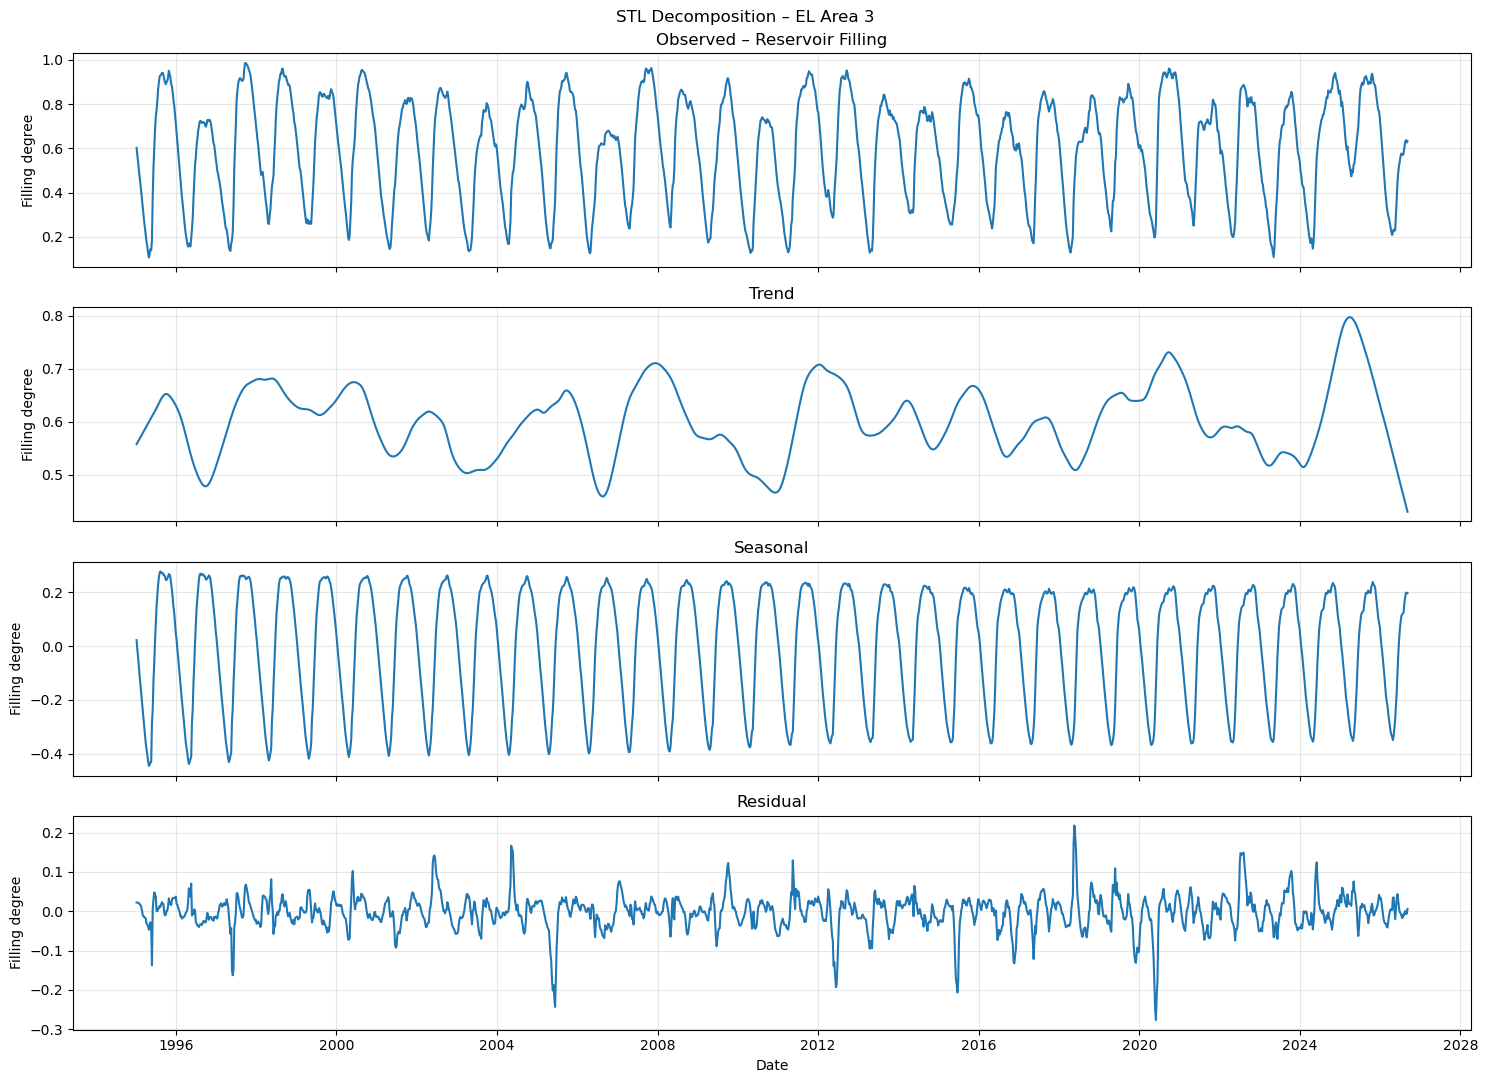

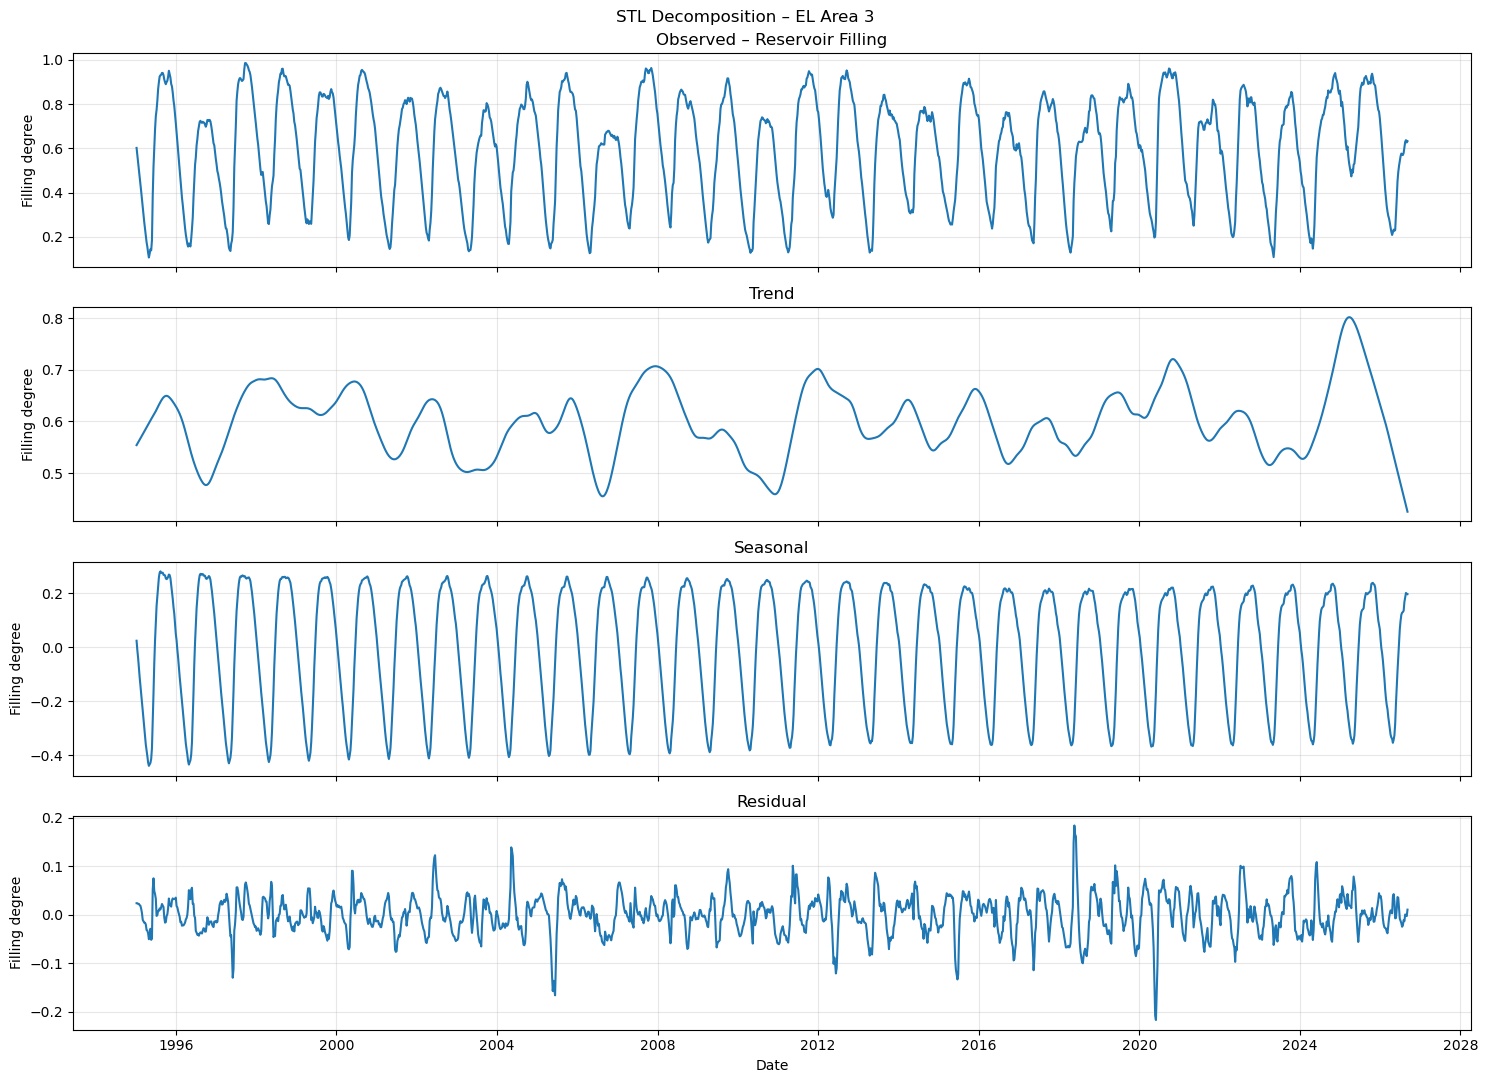

In [38]:
# Test 1: Robust STL
stl_fig_robust = analyze_reservoir_stl(
    reservoirs,
    area_nr=3,
    area_type="EL",
    seasonal=13,
    trend=53,
    robust=True,
    period=52
)

plt.show()


# Test 2: Non-robust STL
stl_fig_nonrobust = analyze_reservoir_stl(
    reservoirs,
    area_nr=3,
    area_type="EL",
    seasonal=13,
    trend=53,
    robust=False,
    period=52
)

plt.show()

#### Spectrogram Analysis of Reservoir Filling Data

In [39]:
def analyze_reservoir_spectrogram(
    df,
    area_nr=3,
    area_type="EL",
    window_length=104,
    window_overlap=52
):
    """
    Create a spectrogram of weekly reservoir filling data.

    Parameters
    ----------
    df : DataFrame
        Reservoir filling dataset.
    area_nr : int
        Electricity area number.
    area_type : str
        Area type, e.g. EL.
    window_length : int
        Number of weeks in each analysis window.
    window_overlap : int
        Number of overlapping weeks.

    Returns
    -------
    fig : matplotlib Figure
    """

    data = df[
        (df["omrType"] == area_type) &
        (df["omrnr"] == area_nr)
    ].copy()

    if data.empty:
        raise ValueError(
            f"No data found for {area_type} area {area_nr}."
        )

    data["dato_Id"] = pd.to_datetime(data["dato_Id"])

    series = (
        data.groupby("dato_Id")["fyllingsgrad"]
        .mean()
        .sort_index()
    )

    # Weekly observations
    series = series.resample("W-SUN").mean()

    # Interpolate missing observations
    series = series.interpolate(method="time")

    if series.isna().any():
        raise ValueError(
            "Missing values remain in the weekly time series."
        )

    if window_length < 2:
        raise ValueError(
            "window_length must be at least 2."
        )

    if not 0 <= window_overlap < window_length:
        raise ValueError(
            "window_overlap must be >= 0 and < window_length."
        )

    if window_length > len(series):
        raise ValueError(
            "window_length cannot exceed the number of observations."
        )

    # Calculate spectrogram
    frequencies, times, power = spectrogram(
        series.to_numpy(),
        fs=1,
        window="hann",
        nperseg=window_length,
        noverlap=window_overlap,
        detrend="linear",
        scaling="density",
        mode="psd"
    )

    # Convert frequencies to cycles per year
    frequencies_per_year = frequencies * 52

    # Convert relative time to calendar dates
    dates = (
        series.index[0]
        + pd.to_timedelta(times * 7, unit="D")
    )

    fig, ax = plt.subplots(figsize=(15, 6))

    mesh = ax.pcolormesh(
        dates,
        frequencies_per_year,
        10 * np.log10(np.maximum(power, 1e-12)),
        shading="auto"
    )

    ax.set_title(
        f"Spectrogram – Reservoir Filling, {area_type} Area {area_nr}"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Frequency (cycles/year)")

    colorbar = fig.colorbar(mesh, ax=ax)
    colorbar.set_label("Power spectral density (dB)")

    ax.grid(alpha=0.2)

    plt.xticks(rotation=45)
    plt.tight_layout()

    return fig

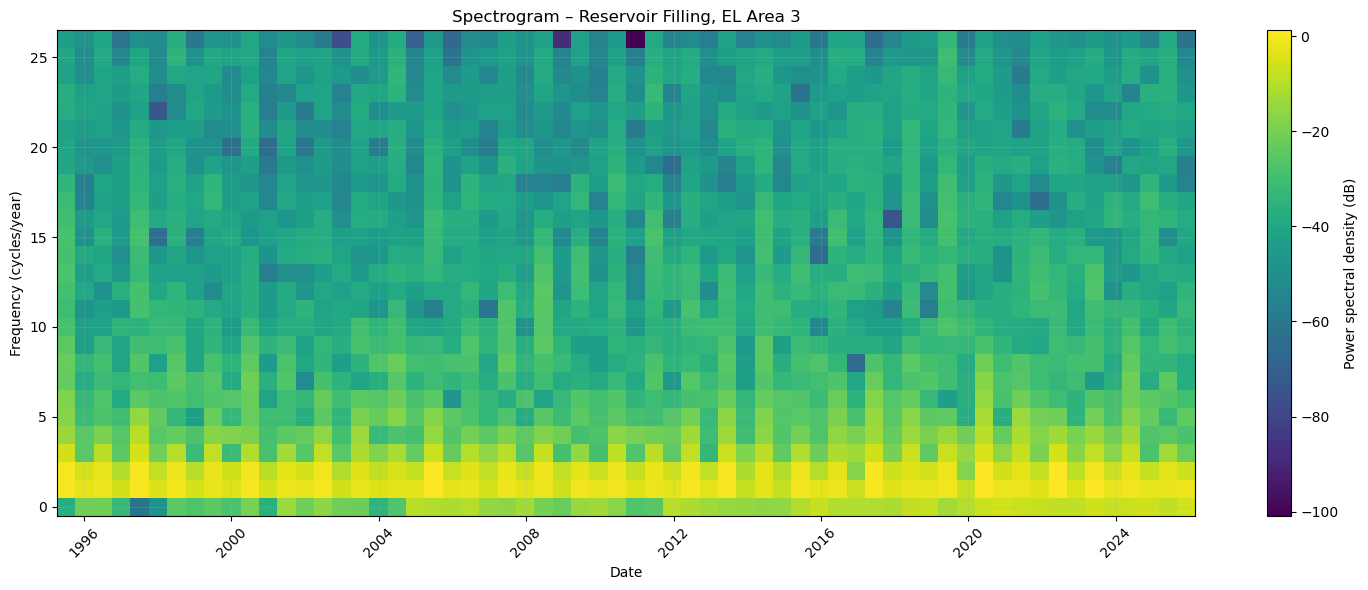

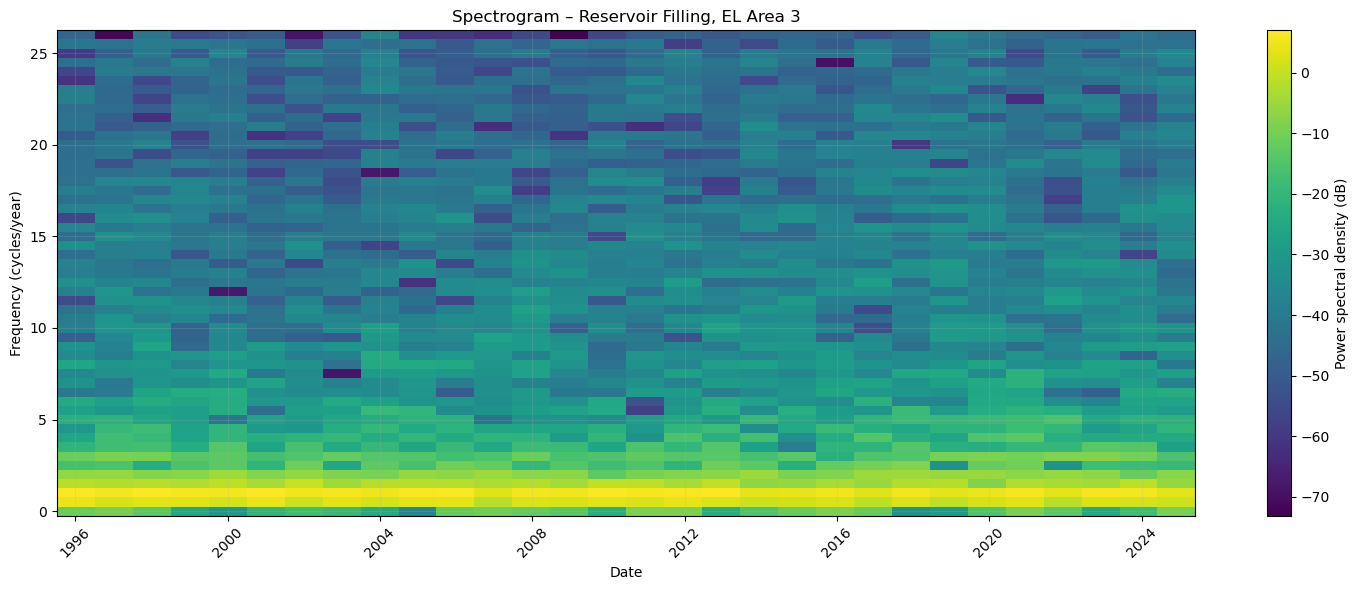

In [40]:
# Test 1: 52-week window and 26-week overlap
spectrogram_fig_1 = analyze_reservoir_spectrogram(
    reservoirs,
    area_nr=3,
    area_type="EL",
    window_length=52,
    window_overlap=26
)

plt.show()


# Test 2: 104-week window and 52-week overlap
spectrogram_fig_2 = analyze_reservoir_spectrogram(
    reservoirs,
    area_nr=3,
    area_type="EL",
    window_length=104,
    window_overlap=52
)

plt.show()

Two different spectrogram configurations are compared: a 52-week window with 26-week overlap and a 104-week window with 52-week overlap.

The choice of window length affects the balance between time resolution and frequency resolution. A shorter window provides better information about when changes occur, while a longer window provides better frequency resolution.

Comparing these configurations helps show how the selected parameters influence the interpretation of the reservoir filling time series. The results should be considered together because neither configuration provides the best resolution in both time and frequency.

#### Save Analysis Figures

In [20]:
FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

precipitation_fig.savefig(
    FIGURE_DIR / "precipitation_DCT_SPC.png",
    dpi=300,
    bbox_inches="tight"
)

temperature_fig.savefig(
    FIGURE_DIR / "temperature_LOF.png",
    dpi=300,
    bbox_inches="tight"
)

stl_fig_robust.savefig(
    FIGURE_DIR / "reservoir_STL_robust.png",
    dpi=300,
    bbox_inches="tight"
)

stl_fig_nonrobust.savefig(
    FIGURE_DIR / "reservoir_STL_nonrobust.png",
    dpi=300,
    bbox_inches="tight"
)

spectrogram_fig_1.savefig(
    FIGURE_DIR / "reservoir_spectrogram_52.png",
    dpi=300,
    bbox_inches="tight"
)

spectrogram_fig_2.savefig(
    FIGURE_DIR / "reservoir_spectrogram_104.png",
    dpi=300,
    bbox_inches="tight"
)

print("Figures saved in:", FIGURE_DIR)

Figures saved in: c:\Users\Khali\OneDrive\Desktop\IND320\Notbook\Part3\figures


In [21]:
print("WEATHER DATA")
print("Number of hourly observations:", len(NO3_weather_average))
print(
    "Time period:",
    NO3_weather_average["time"].min(),
    "to",
    NO3_weather_average["time"].max()
)

print("\nPRECIPITATION ANALYSIS")
print(
    "Number of outliers:",
    precipitation_summary["number_of_outliers"]
)
print(
    "Percentage of outliers:",
    round(precipitation_summary["percentage_outliers"], 2),
    "%"
)

print("\nTEMPERATURE ANALYSIS")
print(
    "Number of anomalies:",
    temperature_summary["number_of_anomalies"]
)
print(
    "Percentage of anomalies:",
    round(temperature_summary["percentage_anomalies"], 2),
    "%"
)

print("\nRESERVOIR DATA")
print("Number of observations:", len(reservoirs))
print(
    "Date range:",
    reservoirs["dato_Id"].min(),
    "to",
    reservoirs["dato_Id"].max()
)

WEATHER DATA
Number of hourly observations: 8784
Time period: 2024-01-01 00:00:00 to 2024-12-31 23:00:00

PRECIPITATION ANALYSIS
Number of outliers: 822
Percentage of outliers: 9.36 %

TEMPERATURE ANALYSIS
Number of anomalies: 88
Percentage of anomalies: 1.0 %

RESERVOIR DATA
Number of observations: 14877
Date range: 1995-01-08 00:00:00 to 2026-09-06 00:00:00


The analysis investigates data quality in geographical, weather, and reservoir filling datasets using several methods.

The geographical analysis connects randomly generated locations to electricity areas and identifies 817 locations in NO3. The weather analysis applies DCT and robust statistical control limits to precipitation data, identifying 822 potential outliers. LOF is used to identify approximately 88 potential temperature anomalies.

For reservoir filling data, STL decomposition separates the time series into trend, seasonal, and residual components. Spectrogram analysis is also used to investigate frequency patterns and compare different window configurations.

The methods provide different perspectives on data quality and time series behaviour. However, detected anomalies should not automatically be treated as errors.

##### AI Usage Description

AI tools were used as supporting tools during the project.

Used to:

- Understand Python libraries and statistical methods.
- Get assistance with Python code structure and debugging.
- Understand the Open-Meteo API.
- Improve explanations and documentation.
- Review the implementation of data quality methods.

All generated code was reviewed, adapted and tested
in the local Jupyter Notebook environment.


##### Work Log (300–500 words)


##### Project work and experience

During Project Work Part 3, I worked with data quality
analysis using geographical, meteorological and reservoir
data. The main development environment was Jupyter Notebook,
where I organised the project into sections covering data
collection, data processing, analysis and visualisation.

I started by setting up the project structure and importing
the required Python libraries. I used GeoPandas and Shapely
to work with geographical data from NVE. The electricity
price areas were downloaded, inspected and visualised.
I also implemented random sampling of geographical points
inside the NO3 area.

For meteorological data, I used the Open-Meteo Archive API
to retrieve hourly historical ERA5 data for 2024. The
download included temperature and precipitation. Downloading
data for many locations was challenging because some API
requests failed, including requests returning HTTP 429
errors. I therefore had to inspect the download results
and calculate average weather values using the successfully
downloaded locations.

For precipitation analysis, I implemented Discrete Cosine
Transform filtering to obtain seasonally adjusted variations.
I used robust statistics to calculate SPC boundaries and
identify unusual observations. For temperature analysis,
I implemented Local Outlier Factor and tested different
outlier proportions.

I also worked with reservoir filling data from
Magasinstatistikk. Before performing time series analysis,
I inspected duplicate dates and prepared the data for
weekly analysis. I implemented STL decomposition to
separate trend, seasonal and residual components. In
addition, I created a spectrogram function and tested
different window lengths and overlap settings.

The Streamlit part of the project involved [describe the
pages and features you implemented]. I used [describe how
you connected the data and added the analysis plots].
One challenge was [describe a real challenge you experienced].
I addressed this by [describe what you did].

This project improved my understanding of
geographical data, API communication, data quality,
time series analysis and Python visualisation. It also
gave me practical experience in organising analytical
code and presenting results through a web application.

#### References

1. Norwegian Water Resources and Energy Directorate (NVE).
   NVE Atlas.
   https://atlas.nve.no/

2. Norwegian Water Resources and Energy Directorate (NVE).
   GIS downloads.
   https://nedlasting.nve.no/gis/

3. Open-Meteo.
   Historical Weather API Documentation.
   https://open-meteo.com/en/docs/historical-weather-api

4. Open-Meteo.
   Archive API.
   https://archive-api.open-meteo.com/

5. Scikit-learn.
   Local Outlier Factor Documentation.
   https://scikit-learn.org/stable/modules/generated/
   sklearn.neighbors.LocalOutlierFactor.html

6. Statsmodels.
   STL Decomposition Documentation.
   https://www.statsmodels.org/stable/generated/
   statsmodels.tsa.seasonal.STL.html

7. SciPy.
   Discrete Cosine Transform Documentation.
   https://docs.scipy.org/doc/scipy/reference/generated/
   scipy.fft.dct.html

8. SciPy.
   Spectrogram Documentation.
   https://docs.scipy.org/doc/scipy/reference/generated/
   scipy.signal.spectrogram.html